# First Neural Network

## Imports and Settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from utils import *


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

set_seed(42)

Using device: cpu


## Load Data

Load in our saved data from the preprocessing step.

In [2]:
X_train, y_train, X_val, y_val, X_test, y_test, train_ds, val_ds, test_ds, feature_cols, target_col, idx_to_label = load_data()

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape} | y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test.shape}")
print(f"Classes ({len(idx_to_label)}): {list(idx_to_label.values())}")

X_train: torch.Size([5475, 561]) | y_train: torch.Size([5475])
X_val:   torch.Size([1877, 561]) | y_val:   torch.Size([1877])
X_test:  torch.Size([2947, 561]) | y_test:  torch.Size([2947])
Classes (6): ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']


Prepare our data loaders, and must remember to shuffle.

In [3]:
BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)

print(f"{len(train_loader)} training batches of size {BATCH_SIZE} per epoch.")

86 training batches of size 64 per epoch.


## Single-Hidden-Layer MLP

In [4]:
class SingleHiddenLayerMLP(nn.Module):
    def __init__(self, input_dim=561, hidden_dim=64, num_classes=6, activation="relu"):
        super().__init__()
        self.activation_name = activation.lower()

        activation_mapping = {
            "relu": nn.ReLU(),
            "sigmoid": nn.Sigmoid(),
            "tanh": nn.Tanh()
        }
        if self.activation_name not in activation_mapping:
            raise ValueError(f"Activation '{activation}' not supported.")

        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.activation = activation_mapping[self.activation_name]
        self.fc2 = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        a1 = self.activation(self.fc1(x))
        logits = self.fc2(a1)
        return logits


sample_mlp = SingleHiddenLayerMLP()
total_params = sum(p.numel() for p in sample_mlp.parameters() if p.requires_grad)

print(sample_mlp)
print(f"Trainable parameters: {total_params}")

SingleHiddenLayerMLP(
  (fc1): Linear(in_features=561, out_features=64, bias=True)
  (activation): ReLU()
  (fc2): Linear(in_features=64, out_features=6, bias=True)
)
Trainable parameters: 36358


### Sanity checks

#### Initial Loss

For a classification with balanced classes (established in part 1), a well-initialized network would predict randomly thus yielding roughly equal probabilities $1/6$. And as we will be using `CrossEntropyLoss`, the expected loss should be $-\ln(1/6) \approx 1.79$.

In [5]:
theoretical_loss = -np.log(1.0 / 6.0)

criterion = nn.CrossEntropyLoss()
sample_mlp.eval()
with torch.no_grad():
    logits = sample_mlp(X_train)
    observed_loss = criterion(logits, y_train).item()

print(f"Theoretical Initial Loss (-ln(1/6)): {theoretical_loss:.4f}")
print(f"Observed Initial Loss: {observed_loss:.4f}")
print(f"Absolute Difference: {abs(observed_loss - theoretical_loss):.4f}")
if abs(observed_loss - theoretical_loss) < 0.25:
    print("PASS: Observed loss matches theoretical expectation. Weight initialization is sound.")
else:
    print("WARNING: Initial loss diverges significantly from expectation.")

Theoretical Initial Loss (-ln(1/6)): 1.7918
Observed Initial Loss: 1.7972
Absolute Difference: 0.0054
PASS: Observed loss matches theoretical expectation. Weight initialization is sound.


#### Overfit a Small Batch

A strong neural network should be able to overfit a small mini-batch easily.

In [6]:

# Create a single-batch DataLoader
tiny_loader = DataLoader(
    TensorDataset(X_train[:BATCH_SIZE], y_train[:BATCH_SIZE]),
    batch_size=BATCH_SIZE
)

overfit_model = SingleHiddenLayerMLP().to(device)
overfit_opt = torch.optim.Adam(overfit_model.parameters(), lr=0.01)

history = train_model(
    overfit_model, tiny_loader, tiny_loader, criterion, overfit_opt,
    n_epochs=100, device=device, verbose_every=0
)

start_loss = history["train_loss"][0]
final_loss = history["val_loss"][-1]
final_acc  = history["val_acc"][-1]

print(f"Mini-batch starting loss:   {start_loss:.4f}")
print(f"Mini-batch final loss:      {final_loss:.4f}")
print(f"Mini-batch final accuracy:  {final_acc * 100:.2f}%")

if final_acc >= 1.0 and final_loss < 0.01:
    print("PASS: Model overfits the tiny batch. Backprop & gradient updates are bug-free.")
else:
    print("FAIL: Model failed to overfit tiny batch.")

Mini-batch starting loss:   1.8756
Mini-batch final loss:      0.0005
Mini-batch final accuracy:  100.00%
PASS: Model overfits the tiny batch. Backprop & gradient updates are bug-free.


As training and evaluating will be used a lot, we defined some helper functions in utils.py. The above test demonstrates that our pipeline works.

### Hyperparameters tuning

Here we will test $3 \times 3$ combinations of activations and optimizers. For each one, we will perform an LR range test to pick the best learning rate (2 orders of magnitudes lower than the minimum, I did try only 1 order of magnitude but it makes some combinations unstable so I decided to use 2 and increase the number of epochs) for each combination for use in the full training with early stopping.

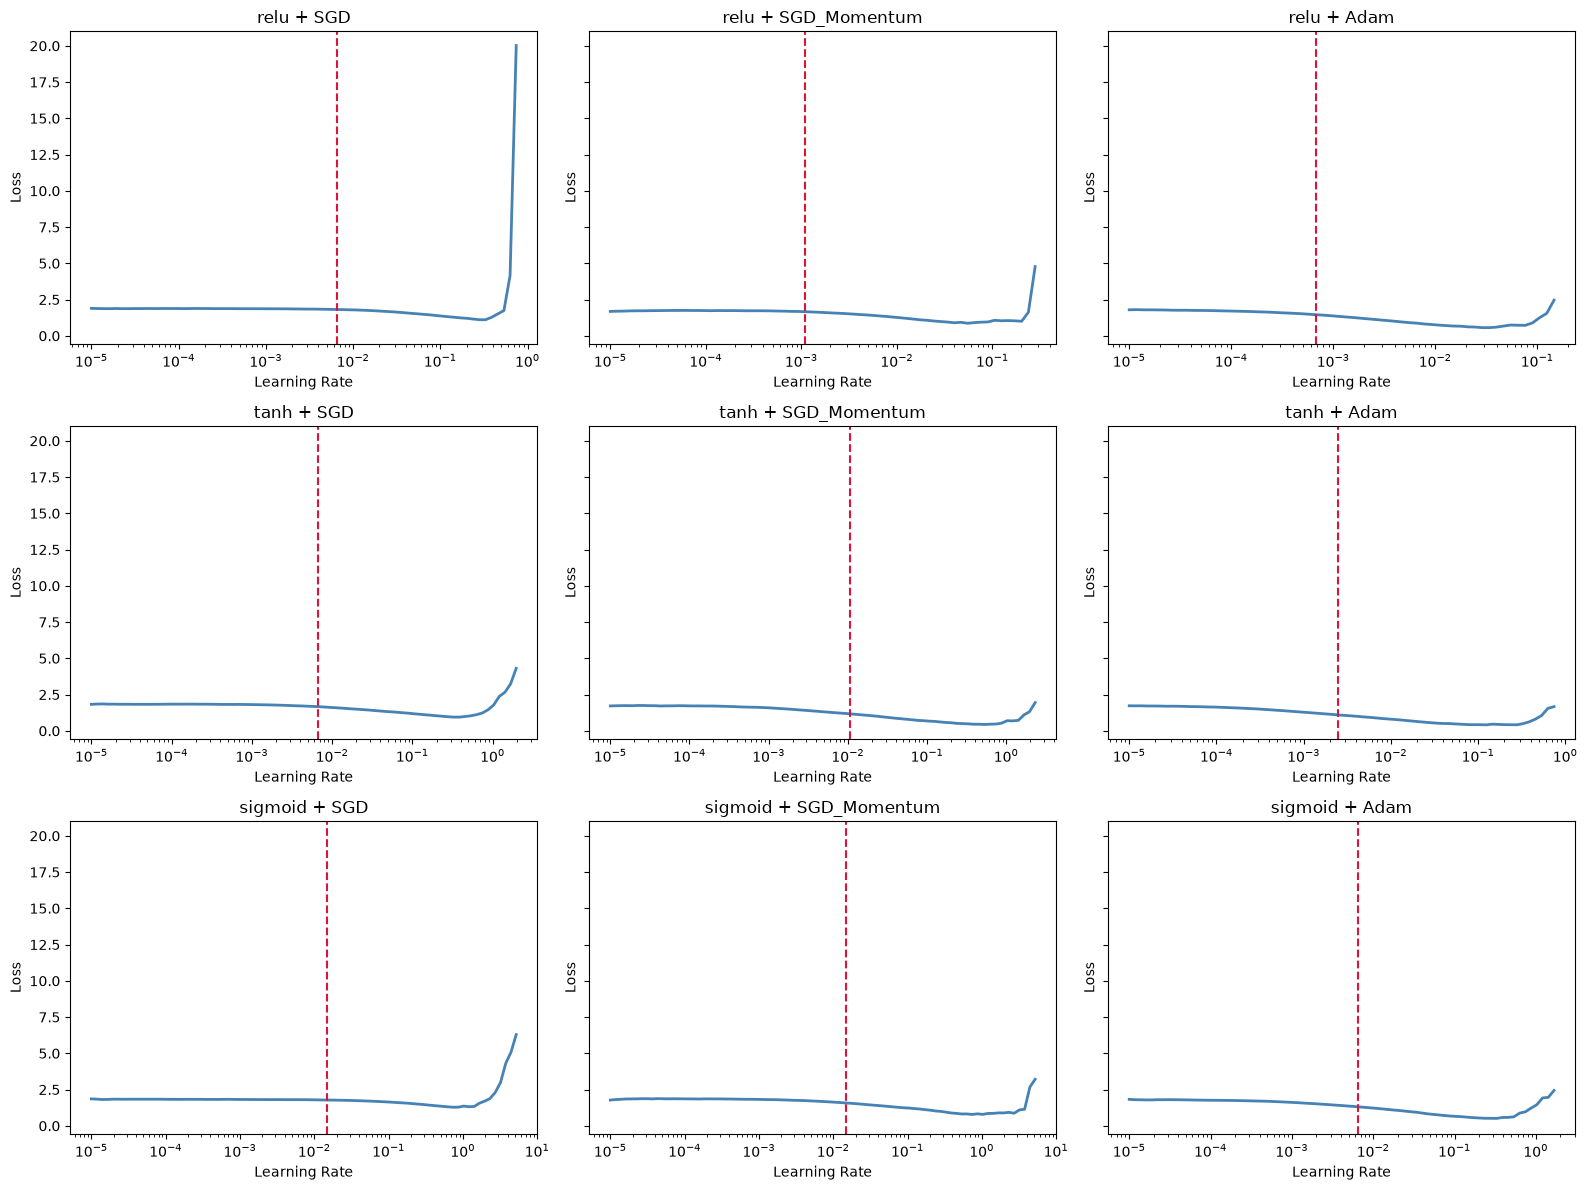

In [24]:
activations = ["relu", "tanh", "sigmoid"]
optimizers = ["SGD", "SGD_Momentum", "Adam"]

def get_optimizer_fn(opt_name):
    if opt_name == "SGD":
        return lambda params, lr: torch.optim.SGD(params, lr=lr)
    elif opt_name == "SGD_Momentum":
        return lambda params, lr: torch.optim.SGD(params, lr=lr, momentum=0.9)
    elif opt_name == "Adam":
        return lambda params, lr: torch.optim.Adam(params, lr=lr)


tuned_lrs = {}
fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharey=True)

for i, act in enumerate(activations):
    tuned_lrs[act] = {}
    for j, opt_name in enumerate(optimizers):
        model = SingleHiddenLayerMLP(activation=act).to(device)
        make_optimizer = get_optimizer_fn(opt_name)

        lrs, losses = lr_range_test(
            model, train_loader, criterion, make_optimizer,
            lr_min=1e-5, lr_max=10.0, device=device
        )

        min_lr = lrs[int(np.argmin(losses))]
        best_lr = min_lr / 5e1

        tuned_lrs[act][opt_name] = best_lr

        ax = axes[i, j]
        ax.plot(lrs, losses, color="steelblue", lw=2)
        ax.axvline(best_lr, color="crimson", ls="--", label=f"Tuned: {best_lr:.4f}")
        ax.set_xscale("log")
        ax.set_title(f"{act} + {opt_name}")
        ax.set_xlabel("Learning Rate")
        ax.set_ylabel("Loss")

plt.tight_layout()
plt.show()

A common semi-trend is that the learning rate for Vanilla SGD > SGD with momentum > Adam which is theoretically sound:
- Vanilla SGD needs higher LR to converge faster as it does not have any speed up mechanism.
- SGD with momentum accumulates past velocity when it's confident that it's heading in the correct direction.
- Adam adapts its learning rate similar to momentum but with feature scales as well.

Epoch 01/100 | Train Loss: 1.2497, Acc: 62.43% | Val Loss: 0.9163, Acc: 83.43%, Macro F1: 82.18%
Epoch 100/100 | Train Loss: 0.0371, Acc: 99.01% | Val Loss: 0.1266, Acc: 95.15%, Macro F1: 95.70%
Epoch 01/100 | Train Loss: 1.1004, Acc: 62.70% | Val Loss: 0.7180, Acc: 84.07%, Macro F1: 83.85%
Early stopping triggered at epoch 79. Best val loss at epoch 59.
Epoch 01/100 | Train Loss: 0.5918, Acc: 80.73% | Val Loss: 0.3027, Acc: 91.85%, Macro F1: 92.59%
Early stopping triggered at epoch 31. Best val loss at epoch 11.
Epoch 01/100 | Train Loss: 1.1084, Acc: 68.15% | Val Loss: 0.8410, Acc: 82.74%, Macro F1: 82.05%
Epoch 100/100 | Train Loss: 0.0396, Acc: 99.00% | Val Loss: 0.1407, Acc: 94.57%, Macro F1: 95.13%
Epoch 01/100 | Train Loss: 0.5030, Acc: 83.00% | Val Loss: 0.2025, Acc: 93.39%, Macro F1: 94.12%
Early stopping triggered at epoch 30. Best val loss at epoch 10.
Epoch 01/100 | Train Loss: 0.3825, Acc: 87.45% | Val Loss: 0.1912, Acc: 92.49%, Macro F1: 93.22%
Early stopping triggered at

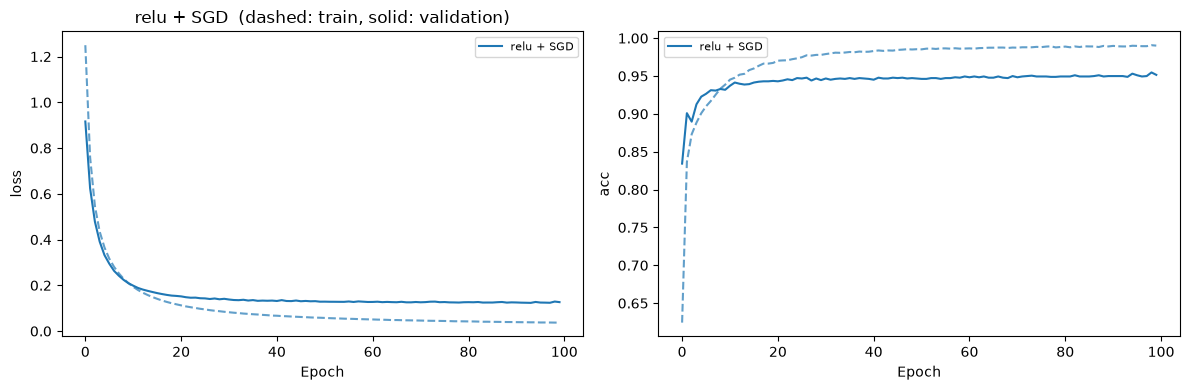

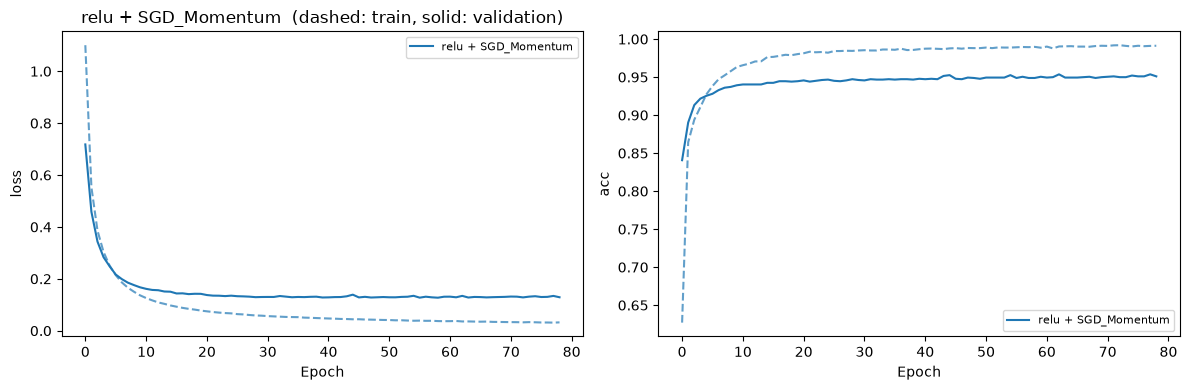

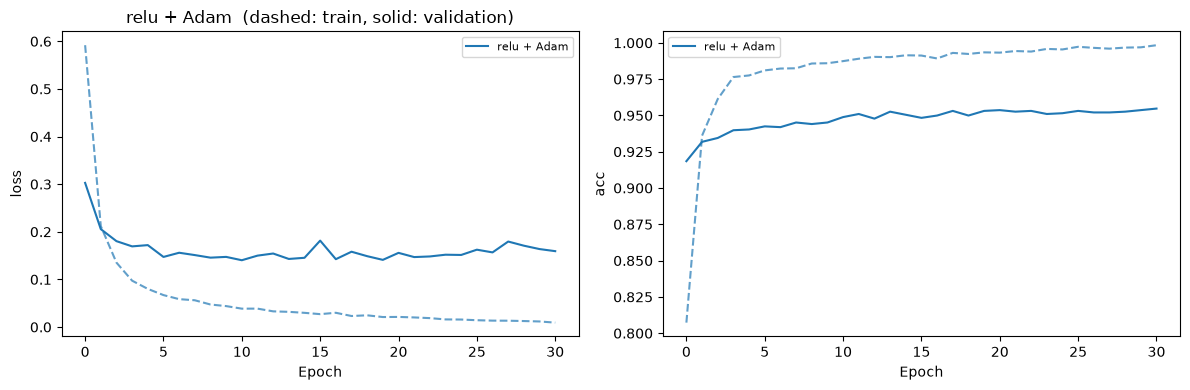

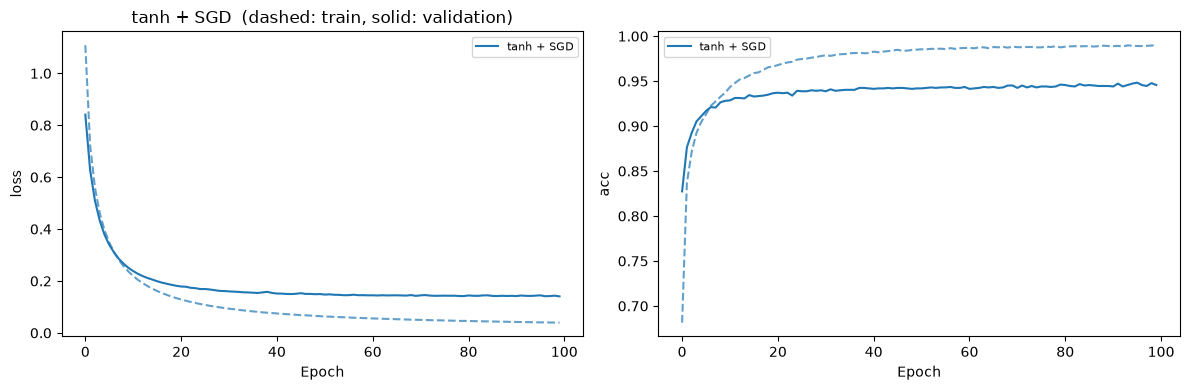

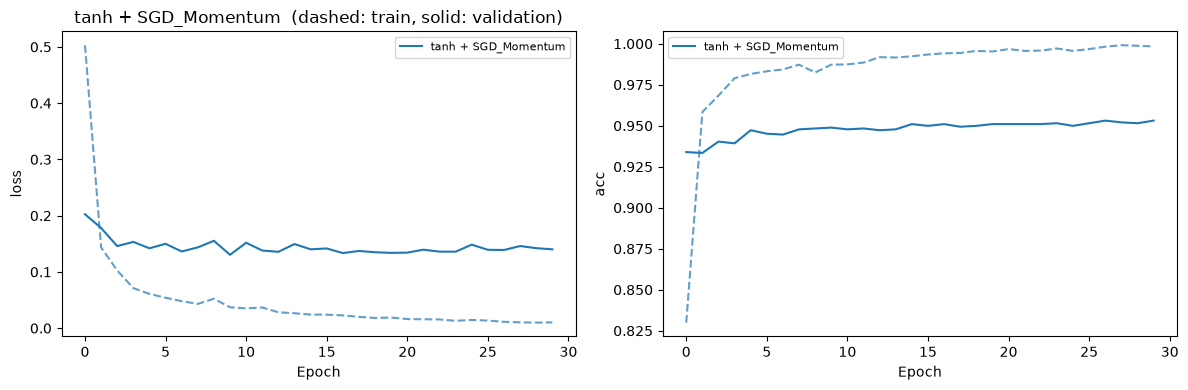

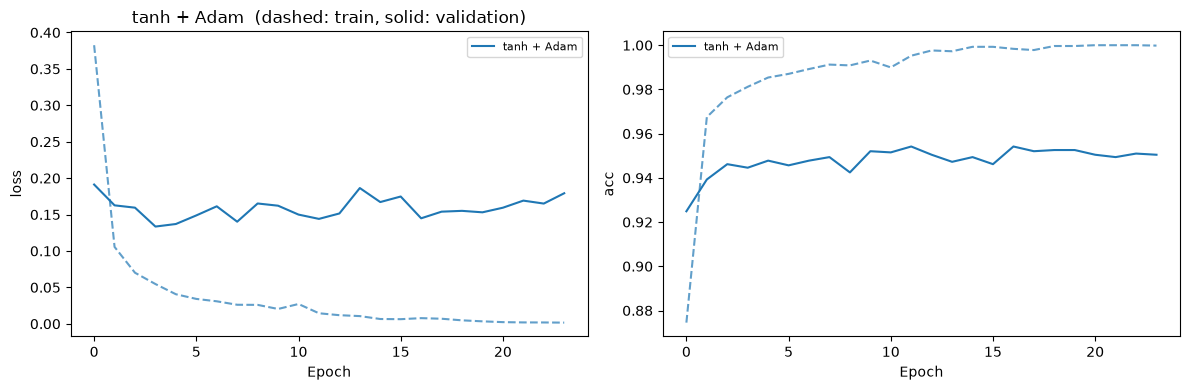

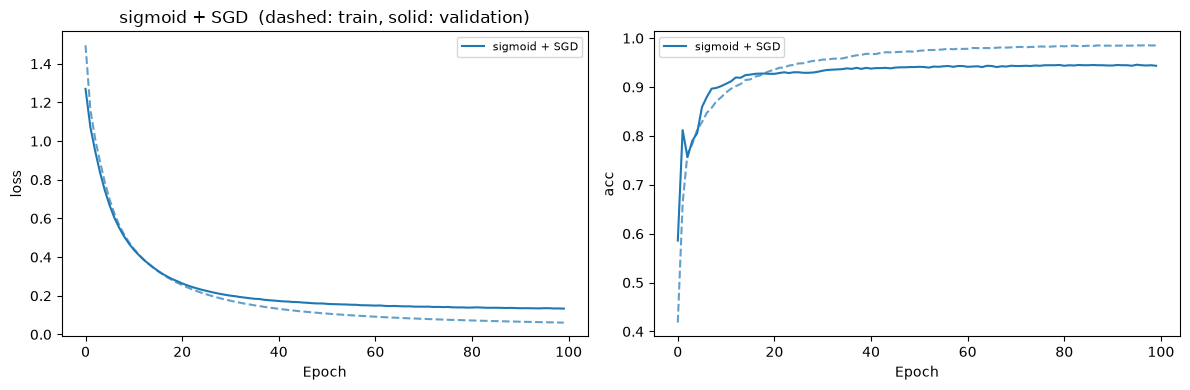

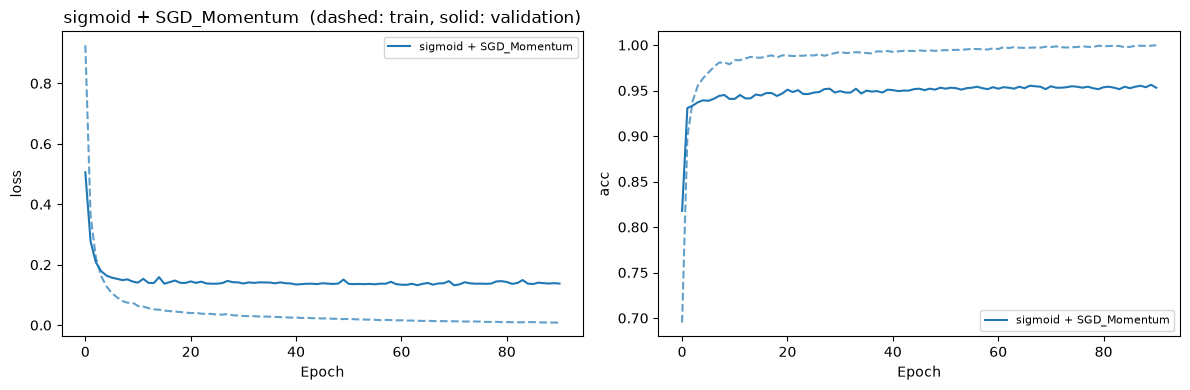

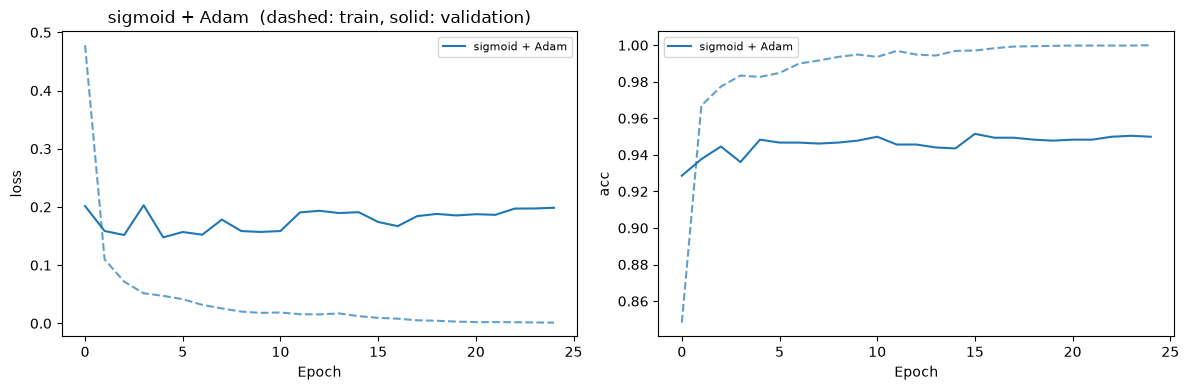

,Activation,Optimizer,Tuned LR,Best Epoch,Train Accuracy (%),Train Loss,Val Accuracy (%),Val Loss,Val Macro F1 (%)
0,sigmoid,SGD_Momentum,0.01485,71,99.78,0.0127,95.47,0.1321,95.93
1,relu,Adam,0.00068,11,98.74,0.0386,94.89,0.1403,95.48
2,relu,SGD,0.00659,94,98.90,0.0384,94.89,0.1234,95.46
3,tanh,SGD_Momentum,0.01073,10,98.72,0.0372,94.89,0.1304,95.44
4,relu,SGD_Momentum,0.00110,59,98.98,0.0372,94.89,0.1273,95.42
5,sigmoid,Adam,0.00659,5,98.26,0.0473,94.83,0.1477,95.37
6,tanh,SGD,0.00659,100,99.00,0.0396,94.57,0.1407,95.13
7,tanh,Adam,0.00248,4,98.12,0.0546,94.46,0.1335,94.96
8,sigmoid,SGD,0.01485,100,98.50,0.0610,94.35,0.1335,94.92


In [25]:
results = []
comparison_histories = {}

for act in activations:
    comparison_histories[act] = {}
    for opt_name in optimizers:
        model = SingleHiddenLayerMLP(activation=act).to(device)
        lr = tuned_lrs[act][opt_name]
        opt = get_optimizer_fn(opt_name)(model.parameters(), lr=lr)

        hist = train_model(
            model, train_loader, val_loader, criterion, opt,
            n_epochs=100, device=device, early_stopping_patience=20, verbose_every=100
        )

        best_ep = hist["best_epoch"]
        train_acc = hist["train_acc"][best_ep - 1]
        train_loss = hist["train_loss"][best_ep - 1]
        val_acc = hist["val_acc"][best_ep - 1]
        val_loss = hist["val_loss"][best_ep - 1]
        val_f1 = hist["val_f1"][best_ep - 1]
        comparison_histories[act][opt_name] = {"model": model, "history": hist}

        results.append({
            "Activation": act,
            "Optimizer": opt_name,
            "Tuned LR": f"{lr:.5f}",
            "Best Epoch": best_ep,
            "Train Accuracy (%)": round(train_acc * 100, 2),
            "Train Loss": round(train_loss, 4),
            "Val Accuracy (%)": round(val_acc * 100, 2),
            "Val Loss": round(val_loss, 4),
            "Val Macro F1 (%)": round(val_f1 * 100, 2),
        })

for act in activations:
    for opt_name in optimizers:
        plot_curves(
            title=f"{act} + {opt_name}",
            hists=comparison_histories[act][opt_name]["history"]
        )

summary_df = pd.DataFrame(results).sort_values(by="Val Macro F1 (%)", ascending=False).reset_index(drop=True)
summary_df

Judging by the learning curves,
- the learning rates seem to be reasonable for most, some oscillate a bit but not substantial while others could do with a higher LR to converge faster. However, all have converged (or at least close enough with very diminishing returns).
- we also observe some losses slightly increasing and every model achieving at least 98% training accuracy which is a sign of overfitting.
- In our case, Adam doesn't seem to give much gain as our data is fairly well standardized.
- It is interesting how Tanh and Sigmoid outperforms ReLU. However, firstly, we only have one hidden layer so there is no vanishing gradients, and secondly, the features are 0-centered, so Tanh can have more of an advantage than ReLU which zeroes out negative values.

These results are only slightly better than our logistic regression baseline and therefore probably not worth it.

#### Metrics

                    precision    recall  f1-score   support

            LAYING     1.0000    0.9539    0.9764       369
           SITTING     0.9139    0.9006    0.9072       342
          STANDING     0.8654    0.9188    0.8913       357
           WALKING     0.9965    1.0000    0.9983       288
WALKING_DOWNSTAIRS     0.9881    0.9960    0.9920       250
  WALKING_UPSTAIRS     0.9963    0.9852    0.9907       271

          accuracy                         0.9547      1877
         macro avg     0.9600    0.9591    0.9593      1877
      weighted avg     0.9561    0.9547    0.9551      1877



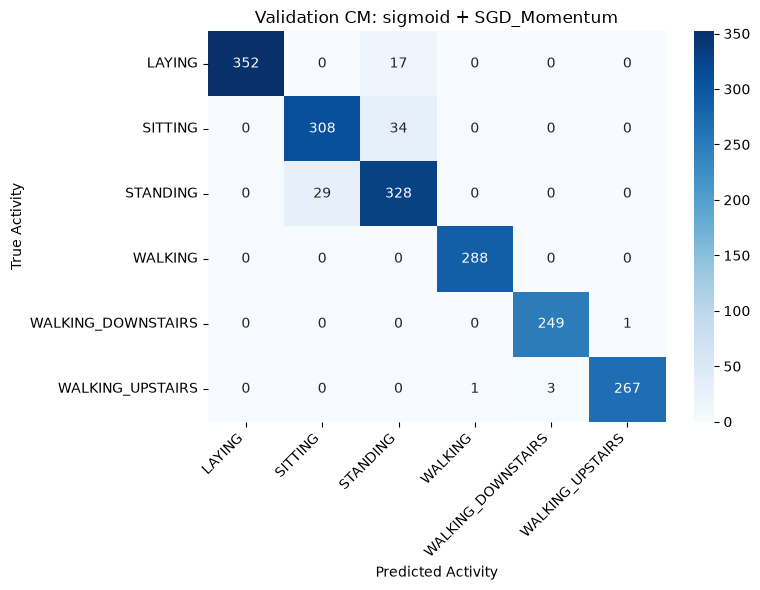

In [26]:
best_row = summary_df.iloc[0]
best_act = best_row["Activation"]
best_opt = best_row["Optimizer"]
best_model = comparison_histories[best_act][best_opt]["model"]

label_names = [idx_to_label[i] for i in range(len(idx_to_label))]
val_loss, val_acc, val_f1, val_preds, val_targets = evaluate_model(best_model, val_loader, criterion, device=device)

print(classification_report(val_targets, val_preds, target_names=label_names, digits=4))

cm_val = confusion_matrix(val_targets, val_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_val, annot=True, fmt="d", cmap="Blues", xticklabels=label_names, yticklabels=label_names)
plt.title(f"Validation CM: {best_row['Activation']} + {best_row['Optimizer']}")
plt.xlabel("Predicted Activity"); plt.ylabel("True Activity")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

Accuracy measures the overall proportion of correct classifications while Macro F1-score gives equal weight ($1/6$) to every single activity class, regardless of sample frequency.

However, since our dataset is fairly balanced as established in part 1, Accuracy and Macro F1 are similar.

But per class F1 and the confusion matrix are useful as they show us which class the model gets right and wrong exactly:
- Dynamic activities (`WALKING`, `WALKING_UPSTAIRS`, `WALKING_DOWNSTAIRS`, `LAYING`) achieve near-perfect F1,
- While the model still encounters ambiguity between `SITTING` and `STANDING`.

So we should look at per-class F1 to diagnose limitations.

### Result Variablity

We test the variablity of our results through many seeds.

In [27]:
SEEDS = [42, 123, 999, 1000, 2026]
configs_to_test = [
    {"name": "ReLU + SGD_Momentum", "act": "relu", "opt": "SGD_Momentum", "lr": tuned_lrs["relu"]["SGD_Momentum"]},
    {"name": "ReLU + Adam", "act": "relu", "opt": "Adam", "lr": tuned_lrs["relu"]["Adam"]}
]

seed_results = {cfg["name"]: {"val_acc": [], "val_f1": []} for cfg in configs_to_test}

for cfg in configs_to_test:
    for s in SEEDS:
        set_seed(s)
        model = SingleHiddenLayerMLP(activation=cfg["act"]).to(device)
        opt = get_optimizer_fn(cfg["opt"])(model.parameters(), lr=cfg["lr"])

        hist = train_model(
            model, train_loader, val_loader, criterion, opt,
            n_epochs=100, device=device, early_stopping_patience=5, verbose_every=0
        )
        best_ep = hist["best_epoch"]
        seed_results[cfg["name"]]["val_acc"].append(hist["val_acc"][best_ep - 1] * 100)
        seed_results[cfg["name"]]["val_f1"].append(hist["val_f1"][best_ep - 1] * 100)

seed_summary = []
for name, m in seed_results.items():
    accs = np.array(m["val_acc"])
    f1s = np.array(m["val_f1"])
    seed_summary.append({
        "Configuration": name,
        "Val Accuracy (Mean ± Std) (%)": f"{accs.mean():.2f} ± {accs.std():.2f}",
        "Val Macro F1 (Mean ± Std) (%)": f"{f1s.mean():.2f} ± {f1s.std():.2f}"
    })

pd.DataFrame(seed_summary)

Early stopping triggered at epoch 47. Best val loss at epoch 42.
Early stopping triggered at epoch 47. Best val loss at epoch 42.
Early stopping triggered at epoch 36. Best val loss at epoch 31.
Early stopping triggered at epoch 70. Best val loss at epoch 65.
Early stopping triggered at epoch 51. Best val loss at epoch 46.
Early stopping triggered at epoch 19. Best val loss at epoch 14.
Early stopping triggered at epoch 14. Best val loss at epoch 9.
Early stopping triggered at epoch 17. Best val loss at epoch 12.
Early stopping triggered at epoch 15. Best val loss at epoch 10.
Early stopping triggered at epoch 16. Best val loss at epoch 11.


,Configuration,Val Accuracy (Mean ± Std) (%),Val Macro F1 (Mean ± Std) (%)
0,ReLU + SGD_Momentum,94.70 ± 0.18,95.25 ± 0.16
1,ReLU + Adam,94.70 ± 0.29,95.29 ± 0.27


Validation accuracy seems very stable. As our accuracies are already high, slight variation in initial weights or shuffling won't change much.